In [10]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import ast
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))
# Now import Model from freeflux
from freeflux.src.freeflux import Model

from HELPER_FREEFLUX_NF import io as nf_io
import numpy as np
from HELPER_FREEFLUX_NF import fit_netfluxes as nf_fit

import seaborn as sns
import analysis.io_func as io_func
import analysis.an_func as an_func
import matplotlib.pyplot as plt

from matplotlib.ticker import LogLocator

from analysis import DistribComp as dc

from analysis import config_13c as config

### flux distribution differences between complete set of sampless (init distrib ) and top scoring subset (accepted dsitrib)
 first global plot  : medians and IQR a
 then focus on a few reactions with a violin plot 

# investigate flux configuration from top scoring samples

In [11]:
# Import general configs:
palette ,cfg =io_func.import_plotconfigs()

In [12]:
condition='TM6' 
model=config.model
net_flux_df=config.full_flux_df(condition)
obj_vals=config.obj_vals(condition)
npercentile=5
accepted_samples=obj_vals[obj_vals<=np.percentile(obj_vals,npercentile)].index

bootstrap_flux_df=config.bootstrap_flux_df(condition)#pd.read_csv(f'{config.DRAWNSAMPLES_FOLDER}/{condition}_drawn_samples.csv',index_col=0)


In [13]:
bootstrap_flux_df#.std(axis=1).sort_values(ascending=False).head(50)

,651,651.1,651.2,651.3,651.4,651.5,651.6,651.7,651.8,651.9,...,770.2,770.3,770.4,892,892.1,892.2,892.3,663,818,820
ASNS1,0.025042,0.025042,0.025042,0.025042,0.025042,0.025042,0.025042,0.025042,0.025042,0.025042,...,0.026292,0.026292,0.026292,0.025934,0.025934,0.025934,0.025934,0.024848,0.025312,0.025011
ASPK,0.111980,0.111980,0.111980,0.111980,0.111980,0.111980,0.111980,0.111980,0.111980,0.111980,...,0.119709,0.119709,0.119709,0.120235,0.120235,0.120235,0.120235,0.111553,0.114861,0.118777
ASPTA,-0.364210,-0.364210,-0.364210,-0.364210,-0.364210,-0.364210,-0.364210,-0.364210,-0.364210,-0.364210,...,-0.372765,-0.372765,-0.372765,-0.362269,-0.362269,-0.362269,-0.362269,-0.465204,-0.347804,-0.419669
ASPTAm,0.034458,0.034458,0.034458,0.034458,0.034458,0.034458,0.034458,0.034458,0.034458,0.034458,...,0.024418,0.024418,0.024418,0.016509,0.016509,0.016509,0.016509,0.137566,0.012822,0.083389
ASAD,0.111980,0.111980,0.111980,0.111980,0.111980,0.111980,0.111980,0.111980,0.111980,0.111980,...,0.119709,0.119709,0.119709,0.120235,0.120235,0.120235,0.120235,0.111553,0.114861,0.118777
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SUCCPItm-2-2,-0.020647,-0.020647,-0.020647,-0.020647,-0.020647,-0.020647,-0.020647,-0.020647,-0.020647,-0.020647,...,-0.020057,-0.020057,-0.020057,-0.041445,-0.041445,-0.041445,-0.041445,-0.143436,-0.124261,-0.312706
SUCFUMtm-2-2,-0.272979,-0.272979,-0.272979,-0.272979,-0.272979,-0.272979,-0.272979,-0.272979,-0.272979,-0.272979,...,0.029987,0.029987,0.029987,0.005895,0.005895,0.005895,0.005895,-0.149879,-0.158578,-0.052498
THRtm+0,0.045825,0.045825,0.045825,0.045825,0.045825,0.045825,0.045825,0.045825,0.045825,0.045825,...,0.048111,0.048111,0.048111,0.047456,0.047456,0.047456,0.047456,0.045470,0.046319,0.045768
biomass_ce,0.246237,0.246237,0.246237,0.246237,0.246237,0.246237,0.246237,0.246237,0.246237,0.246237,...,0.258524,0.258524,0.258524,0.255003,0.255003,0.255003,0.255003,0.244330,0.248893,0.245933


## now violin plot to see difference in flux distributions all vs top (for rxn that stand out)
make sure we take the same number of samples to draw initial dist

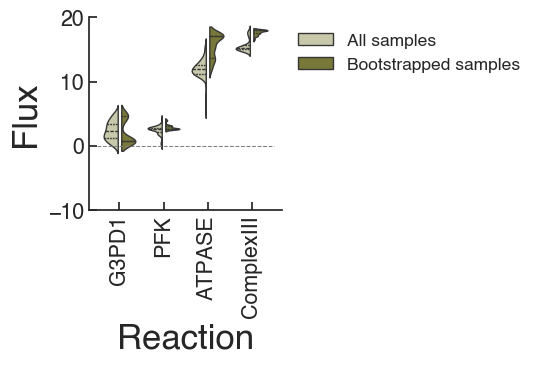

In [14]:
# Assuming `net_flux_df_tm6` is your DataFrame and `sorted_rxnlist` is a list of reactions
# Prepare the data for Seaborn
nselect=20
paletteplot=[palette[3],palette[2]] if condition=='TM6' else [palette[1],palette[0]]


rxn_list_plot= [ 'G3PD1','ATPASE','ComplexIII','PFK'] 
data_all = net_flux_df.loc[rxn_list_plot,np.random.choice(1000,bootstrap_flux_df.shape[1])].T.melt(var_name="Reaction", value_name="Flux")
data_all["Type"] = "All samples"

data_accepted = bootstrap_flux_df.loc[rxn_list_plot].T.melt(var_name="Reaction", value_name="Flux")
data_accepted["Type"] = f"Bootstrapped samples"

# Combine both datasets
data_combined = pd.concat([data_all, data_accepted])
##oreder box plot
oreder=bootstrap_flux_df.loc[rxn_list_plot].mean(axis=1).sort_values()
# Plot with Seaborn
fig,ax = plt.subplots(1,1,figsize=(2.5, 2.5))#,layout='tight')
sns.violinplot(ax=ax,
    data=data_combined,
    x="Reaction",
    y="Flux",
    hue="Type",
    order=oreder.index,
    split=True,  
    inner='quart',  
    gap=0.2,linewidth=1,density_norm ='width',
    # cut=0,
      palette=paletteplot#,flierprops={'markeredgecolor':'.7','alpha':0.6}
)
io_func.scale_rcparams(fig)

# Customize appearance
plt.xticks(rotation=90)
ax.locator_params(axis='y',nbins=5)
ax.set_ylim(-10,ax.get_ylim()[1]  )

ax.set_yticks([-10,0,10,20])
ax.legend(edgecolor='black',loc='upper left',frameon=False,bbox_to_anchor=(1.0, 1))
ax.hlines(y=0, xmin=-0.5, xmax=len(rxn_list_plot)-0.5, **cfg['settings_diagonal'])

# plt.savefig(f'{config.PLOTS_FOLDER}/fig5e_distribchange_violions_KSdiff_bootstrap_{condition}_small.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{config.PLOTS_FOLDER}/fig5e_distribchange_violions_KSdiff_bootstrap_{condition}_small.svg',dpi=300,bbox_inches='tight')

In [6]:
net_flux_df.std(axis=1).sort_values(ascending=False).head(20)

POSQtm        0.810596
ATPASE        0.776666
PItm-2+H      0.724388
H2Otm+0       0.715409
G3PD1         0.704104
PYRtm-1+H     0.673395
CO2tm-1       0.657912
OAAtm-2+2H    0.617268
G3PT          0.612695
PItm-2+2H     0.611197
ACtm-1+H      0.585407
ACALDtm+0     0.582809
NADH2-u6i     0.578105
G3PD2         0.577664
3MOPtm-1+H    0.571646
3MOPtm-1      0.571642
GLUtm-1       0.570673
3MOBtm-1+H    0.558656
3MOBtm-1      0.558628
GLUtm-1+H     0.553409
dtype: float64